In [19]:
import pynq
from pynq import Overlay, allocate
import numpy as np
import matplotlib.pyplot as plt

ol = Overlay("IterativeDesign.bit")
ip = ol.vitis_top_0


In [24]:
print(ol.ip_dict.keys())
print(ol.vitis_top_0)
print(ip.register_map)

dict_keys(['vitis_top_0', 'zynq_ultra_ps_e_0'])
RegisterMap {
  CTRL = Register(AP_START=0, AP_DONE=0, AP_IDLE=1, AP_READY=0, RESERVED_1=0, AUTO_RESTART=0, RESERVED_2=0, INTERRUPT=0, RESERVED_3=0),
  GIER = Register(Enable=0, RESERVED=0),
  IP_IER = Register(CHAN0_INT_EN=0, CHAN1_INT_EN=0, RESERVED_0=0),
  IP_ISR = Register(CHAN0_INT_ST=0, CHAN1_INT_ST=0, RESERVED_0=0),
  image_in_1 = Register(image_in=write-only),
  image_in_2 = Register(image_in=write-only),
  weights_in_1 = Register(weights_in=write-only),
  weights_in_2 = Register(weights_in=write-only),
  depth_out_1 = Register(depth_out=write-only),
  depth_out_2 = Register(depth_out=write-only),
  num_images = Register(num_images=write-only)
}


In [26]:
# ===== Cellule 2 : helpers Q6.10 =====
SCALE = 1 << 10
def to_q610(x):
    q = np.round(np.asarray(x, np.float32) * SCALE)
    return np.clip(q, -32768, 32767).astype(np.int16)
def from_q610(x):
    return np.asarray(x, np.int16).astype(np.float32) / SCALE

In [31]:
# ===== Cellule 3 : buffers + poids (3 blocs = 72992 !) + image =====
N_W = 72992   # <-- 3 blocs (avant 60384 pour 2 blocs)
img_buf = allocate(shape=(3*64*64,), dtype=np.int16)   # 12288 (image CHW)
w_buf   = allocate(shape=(N_W,),     dtype=np.int16)    # poids
out_buf = allocate(shape=(64*64,),   dtype=np.int16)    # 4096  (depth)

w_bin = np.fromfile("weights_q610.bin", dtype=np.int16)
assert w_bin.size == N_W, f"weights_q610.bin={w_bin.size}, attendu {N_W} -> régénère-le depuis le params.h 3 blocs !"
w_buf[:] = w_bin
w_buf.flush()

# image d'entrée (remplace par une vraie image 64x64x3 normalisée [0,1])
img = np.random.rand(64, 64, 3).astype(np.float32)
img_chw = np.transpose(img, (2, 0, 1)).reshape(-1)   # -> CHW aplati
img_buf[:] = to_q610(img_chw)
img_buf.flush()

In [32]:
# ===== Cellule 4 : adresses + num_images + lancer =====
def set_addr(reg, addr):
    setattr(ip.register_map, reg+"_1",  addr        & 0xFFFFFFFF)
    setattr(ip.register_map, reg+"_2", (addr >> 32) & 0xFFFFFFFF)

set_addr("image_in",   img_buf.physical_address)
set_addr("weights_in", w_buf.physical_address)
set_addr("depth_out",  out_buf.physical_address)

ip.register_map.num_images = 1     # <-- NOUVEAU : taille du lot (1 image ici)

ip.register_map.CTRL.AP_START = 1
while ip.register_map.CTRL.AP_DONE == 0:
    pass
out_buf.invalidate()

min=-1.513  max=13.593  mean=9.319


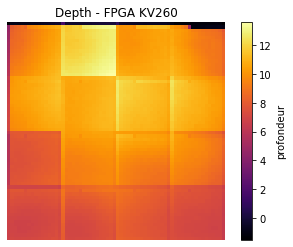

In [33]:
# ===== Cellule 5 : lire + visualiser =====
import matplotlib.pyplot as plt
depth = from_q610(np.array(out_buf)).reshape(64, 64)
print(f"min={depth.min():.3f}  max={depth.max():.3f}  mean={depth.mean():.3f}")
plt.imshow(depth, cmap="inferno"); plt.colorbar(label="profondeur")
plt.title("Depth - FPGA KV260"); plt.axis("off")
plt.savefig("depth_fpga.png", dpi=150, bbox_inches="tight"); plt.show()

In [34]:
# ===== Cellule 6 : benchmark FPS =====
import time
N_WARMUP, N_ITERS = 10, 200
def accel_once():
    ip.register_map.CTRL.AP_START = 1
    while ip.register_map.CTRL.AP_DONE == 0:
        pass

ip.register_map.num_images = 1
for _ in range(N_WARMUP): accel_once()

t = np.empty(N_ITERS)
for i in range(N_ITERS):
    t0 = time.perf_counter(); accel_once(); t[i] = time.perf_counter() - t0
print(f"Accélérateur seul : {t.mean()*1e3:.3f} ms  ->  {1/t.mean():.1f} FPS")

t = np.empty(N_ITERS)
for i in range(N_ITERS):
    t0 = time.perf_counter()
    img_buf[:] = to_q610(img_chw); img_buf.flush()
    accel_once()
    out_buf.invalidate(); _ = np.asarray(out_buf)
    t[i] = time.perf_counter() - t0
print(f"Bout-en-bout      : {t.mean()*1e3:.3f} ms  ->  {1/t.mean():.1f} FPS")

Accélérateur seul : 39.200 ms  ->  25.5 FPS
Bout-en-bout      : 39.615 ms  ->  25.2 FPS


[TEST FPGA vs reference] PASS - erreur max absolue = 0.394776


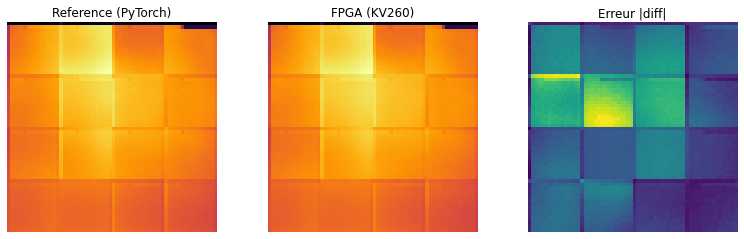

In [35]:
# ===== Cellule : TEST MATERIEL (FPGA vs reference) — equivalent du tb C++ =====
def load_ref(path):
    """Lit un fichier 'shape\\n valeurs...' -> tableau numpy aplati (comme load_tensor du C++)."""
    with open(path) as f:
        f.readline()                                   # 1ere ligne = forme, on l'ignore
        return np.array(f.read().split(), dtype=np.float32)

# 1) Image de REFERENCE (celle qui a produit la reference) -> ordre CHW deja aplati
img_ref = load_ref("input_image.txt")
assert img_ref.size == 3*64*64, f"input_image.txt = {img_ref.size}, attendu 12288"
img_buf[:] = to_q610(img_ref)          # meme quantification Q6.10 que le tb
img_buf.flush()

# 2) Lancer le FPGA sur cette image
ip.register_map.num_images = 1
ip.register_map.CTRL.AP_START = 1
while ip.register_map.CTRL.AP_DONE == 0:
    pass
out_buf.invalidate()

# 3) Comparer sortie FPGA vs reference (comme compare_tensors)
depth_fpga = from_q610(np.array(out_buf))      # 4096 valeurs
depth_ref  = load_ref("final_depth_output.txt")
max_err = float(np.max(np.abs(depth_fpga - depth_ref)))
tol = 0.5                                        # meme tolerance que le tb
verdict = "PASS" if max_err < tol else "FAIL"
print(f"[TEST FPGA vs reference] {verdict} - erreur max absolue = {max_err:.6f}")

# bonus : visualiser cote a cote
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
im0 = ax[0].imshow(depth_ref.reshape(64,64),  cmap="inferno"); ax[0].set_title("Reference (PyTorch)")
im1 = ax[1].imshow(depth_fpga.reshape(64,64), cmap="inferno"); ax[1].set_title("FPGA (KV260)")
im2 = ax[2].imshow(np.abs(depth_fpga-depth_ref).reshape(64,64), cmap="viridis"); ax[2].set_title("Erreur |diff|")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("test_fpga_vs_ref.png", dpi=150); plt.show()